In [1]:
# Runtime dependency check (installs only missing packages in Colab / ephemeral environments)
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pandas": "pandas>=2.0.0",
    "numpy": "numpy>=1.24.0",
    "scipy": "scipy>=1.10.0",
    "statsmodels": "statsmodels>=0.14.0",
    "sklearn": "scikit-learn>=1.3.0",
    "xgboost": "xgboost>=1.7.0",
    "matplotlib": "matplotlib>=3.7.0",
    "seaborn": "seaborn>=0.12.0",
    "joblib": "joblib>=1.3.0",
}

missing = [pkg_spec for mod, pkg_spec in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already available.")

All required packages are already available.


In [2]:
import os
import subprocess
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)

sns.set_theme(style="whitegrid", context="notebook")

IN_COLAB = "google.colab" in sys.modules
GITHUB_REPO_URL = "https://github.com/disulamihisara123/pharmaco-ocd.git"

if IN_COLAB:
    USE_GOOGLE_DRIVE = False
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = "/content/drive/MyDrive/pharmaco-ocd"
    else:
        PROJECT_ROOT = "/content/pharmaco-ocd"
        if not os.path.exists(os.path.join(PROJECT_ROOT, "src", "models.py")):
            print(f"Cloning {GITHUB_REPO_URL} into {PROJECT_ROOT}...")
            subprocess.check_call(["git", "clone", "-q", GITHUB_REPO_URL, PROJECT_ROOT])
else:
    cwd = os.getcwd()
    PROJECT_ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebooks" else cwd

SRC_DIR = os.path.join(PROJECT_ROOT, "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

from data_loader import download_file, download_platform_annotation, get_geo_series_url, parse_series_matrix
from preprocess import check_and_apply_log2, clean_missing_probes, harmonize_cohorts, map_probes_to_genes
from feature_selection import build_candidate_pool, compute_ocd_differential_expression, run_stability_selection
from models import (
    evaluate_external_cohort,
    evaluate_leakage_free_cv,
    get_candidate_classifiers,
    stratify_risk_tier,
    train_and_save_final_model,
)

DATA_RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw")
DATA_PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
DATA_META_DIR = os.path.join(PROJECT_ROOT, "data", "metadata")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "reports", "figures")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")

for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, DATA_META_DIR, FIGURES_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

# Auto-bootstrap harmonized files if running in a fresh Colab runtime without Notebook 01 outputs
if not os.path.exists(os.path.join(DATA_PROCESSED_DIR, "GSE149980_harmonized_zscore.csv.gz")):
    print("Processed data not found locally; running automated Phase 1 download & harmonization...")
    cohorts = {"GSE60190": "GPL6947", "GSE149980": "GPL17077", "GSE83386": "GPL17077", "GSE76826": "GPL17077"}
    gpl_paths = {gpl: download_platform_annotation(gpl, DATA_RAW_DIR) for gpl in set(cohorts.values())}
    gene_exprs = {}
    for gse, gpl in cohorts.items():
        dest = os.path.join(DATA_RAW_DIR, f"{gse}_series_matrix.txt.gz")
        download_file(get_geo_series_url(gse), dest)
        df_e, df_m = parse_series_matrix(dest)
        df_n = check_and_apply_log2(clean_missing_probes(df_e))
        gene_exprs[gse] = map_probes_to_genes(df_n, gpl_paths[gpl])
        df_m.to_csv(os.path.join(DATA_META_DIR, f"{gse}_metadata.csv"))
    harm_z, _ = harmonize_cohorts(gene_exprs, zscore=True)
    for gse, df_h in harm_z.items():
        df_h.to_csv(os.path.join(DATA_PROCESSED_DIR, f"{gse}_harmonized_zscore.csv.gz"), compression="gzip")

print(f"Environment ready ({'Google Colab' if IN_COLAB else 'Local Python'}) | Root: {PROJECT_ROOT}")

Cloning https://github.com/disulamihisara123/pharmaco-ocd.git into /content/pharmaco-ocd...
Processed data not found locally; running automated Phase 1 download & harmonization...
[DOWNLOADING] https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL6947&targ=self&form=text&view=data -> /content/pharmaco-ocd/data/raw/GPL6947_platform.txt.gz
[COMPLETED] Platform annotation saved: /content/pharmaco-ocd/data/raw/GPL6947_platform.txt.gz
[DOWNLOADING] https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL17077&targ=self&form=text&view=data -> /content/pharmaco-ocd/data/raw/GPL17077_platform.txt.gz
[COMPLETED] Platform annotation saved: /content/pharmaco-ocd/data/raw/GPL17077_platform.txt.gz
[DOWNLOADING] https://ftp.ncbi.nlm.nih.gov/geo/series/GSE60nnn/GSE60190/matrix/GSE60190_series_matrix.txt.gz -> /content/pharmaco-ocd/data/raw/GSE60190_series_matrix.txt.gz
[COMPLETED] Download finished: /content/pharmaco-ocd/data/raw/GSE60190_series_matrix.txt.gz
[QC] Data appears already log2-scaled (Min

In [3]:
df60_expr = pd.read_csv(os.path.join(DATA_PROCESSED_DIR, "GSE60190_harmonized_zscore.csv.gz"), index_col=0)
df60_meta = pd.read_csv(os.path.join(DATA_META_DIR, "GSE60190_metadata.csv"), index_col=0)

df149_expr = pd.read_csv(os.path.join(DATA_PROCESSED_DIR, "GSE149980_harmonized_zscore.csv.gz"), index_col=0)
df149_meta = pd.read_csv(os.path.join(DATA_META_DIR, "GSE149980_metadata.csv"), index_col=0).loc[df149_expr.columns]
ctp_mask = df149_meta["title"].str.contains("_CTP_")
X_disc = df149_expr.T.loc[ctp_mask]
y_disc = (df149_meta.loc[ctp_mask, "response status"] == "responder").astype(int).values
g_disc = df149_meta.loc[ctp_mask, "title"].str.split("_").str[0].values

df83_expr = pd.read_csv(os.path.join(DATA_PROCESSED_DIR, "GSE83386_harmonized_zscore.csv.gz"), index_col=0)
df83_meta = pd.read_csv(os.path.join(DATA_META_DIR, "GSE83386_metadata.csv"), index_col=0).loc[df83_expr.columns]
X_ext = df83_expr.T
y_ext = (df83_meta["clinical treatment outcome"] == "responder").astype(int).values
g_ext = df83_meta["cell line"].values

deg_ocd = compute_ocd_differential_expression(df60_expr, df60_meta)
cand_genes = build_candidate_pool(deg_ocd, available_genes=X_disc.columns, n_ocd_top=200)

print(f"Discovery Cohort (GSE149980 CTP): X={X_disc.shape}, Responders={y_disc.sum()}/{len(y_disc)}, Unique Donors={len(np.unique(g_disc))}")
print(f"External Cohort (GSE83386):       X={X_ext.shape}, Responders={y_ext.sum()}/{len(y_ext)}, Unique Cell Lines={len(np.unique(g_ext))}")
print(f"OCD DEGs (p < 0.05): {(deg_ocd['pval'] < 0.05).sum()} | Combined OCD + Pathway Candidate Pool: {len(cand_genes)} genes")
display(deg_ocd.head(10))

Discovery Cohort (GSE149980 CTP): X=(34, 17188), Responders=18/34, Unique Donors=17
External Cohort (GSE83386):       X=(20, 17188), Responders=12/20, Unique Cell Lines=10
OCD DEGs (p < 0.05): 3695 | Combined OCD + Pathway Candidate Pool: 243 genes


,delta_mean,t_stat,abs_t,pval,fdr,pathway
Gene,,,,,,
SNORD109B,-0.763720,-6.852256,6.852256,4.105113e-10,0.000007,OCD Neuropathology
PTPRQ,-0.684245,-5.851195,5.851195,4.658447e-08,0.000199,OCD Neuropathology
EIF5AL1,-0.710426,-5.801929,5.801929,6.876007e-08,0.000199,OCD Neuropathology
OR2T12,-0.635449,-5.778233,5.778233,7.075714e-08,0.000199,OCD Neuropathology
FLJ11235,-0.866138,-6.155114,6.155114,7.209290e-08,0.000199,OCD Neuropathology
RASL11A,-0.759674,-5.880856,5.880856,7.346784e-08,0.000199,OCD Neuropathology
LNPEP,-0.818933,-6.020584,6.020584,8.118365e-08,0.000199,OCD Neuropathology
C6orf57,-1.134614,-6.731589,6.731589,1.234910e-07,0.000265,OCD Neuropathology
KRTAP12-1,-0.601362,-5.574657,5.574657,1.643880e-07,0.000292,OCD Neuropathology


,Model,Sample_ROC_AUC,ROC_AUC_95CI,Donor_ROC_AUC,PR_AUC,Balanced_Acc,F1_Score,Brier_Score,Avg_Fold_Sec
0,XGBoost,0.715278,"[0.530, 0.899]",0.750000,0.786308,0.670139,0.717949,0.238000,0.053562
1,ElasticNet_LogReg,0.635417,"[0.435, 0.852]",0.652778,0.610616,0.645833,0.666667,0.260749,0.002733
2,SVM_RBF,0.562500,"[0.358, 0.763]",0.569444,0.680770,0.496528,0.540541,0.322885,0.002636
3,Dummy_Baseline,0.500000,"[0.324, 0.671]",0.500000,0.529412,0.500000,0.514286,0.500000,0.000743
4,RandomForest,0.479167,"[0.271, 0.699]",0.472222,0.568039,0.493056,0.564103,0.298701,0.368507
5,L2_LogReg,0.500000,"[0.303, 0.736]",0.472222,0.509760,0.555556,0.594595,0.345711,0.006217


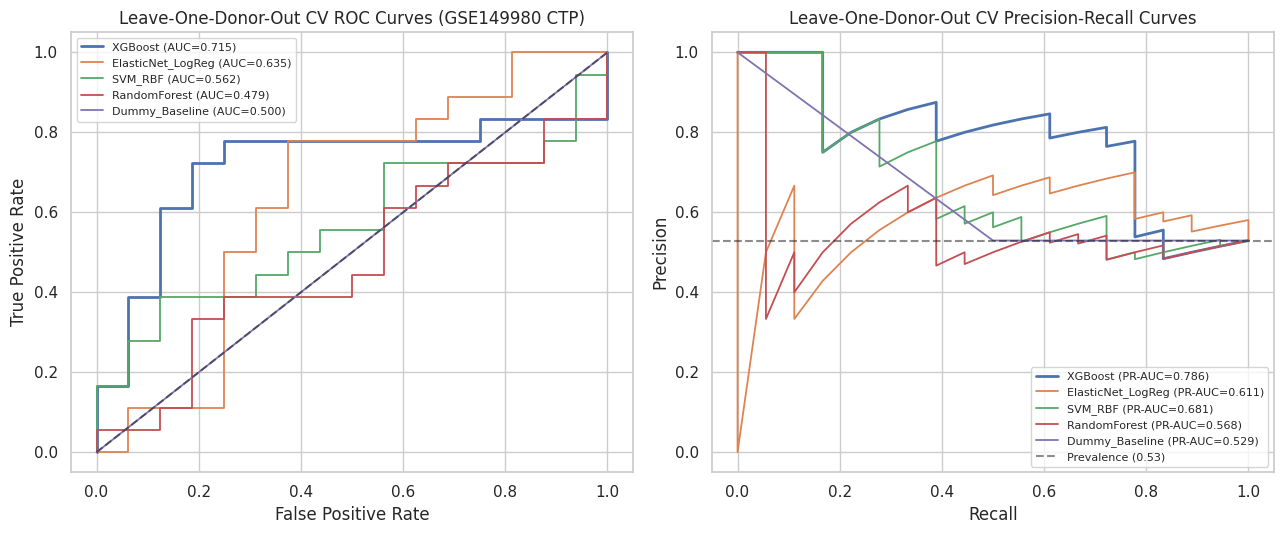

In [4]:
cv_results, oof_probs = evaluate_leakage_free_cv(
    X_disc, y_disc, g_disc, cand_genes, k=15, cv_strategy="logo", random_state=42
)
display(cv_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name in ["XGBoost", "ElasticNet_LogReg", "SVM_RBF", "RandomForest", "Dummy_Baseline"]:
    fpr, tpr, _ = roc_curve(y_disc, oof_probs[name])
    auc_val = cv_results.loc[cv_results["Model"] == name, "Sample_ROC_AUC"].values[0]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})", linewidth=2 if name == "XGBoost" else 1.3)

    prec, rec, _ = precision_recall_curve(y_disc, oof_probs[name])
    pr_val = cv_results.loc[cv_results["Model"] == name, "PR_AUC"].values[0]
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={pr_val:.3f})", linewidth=2 if name == "XGBoost" else 1.3)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Leave-One-Donor-Out CV ROC Curves (GSE149980 CTP)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8)

axes[1].axhline(y_disc.mean(), color="k", linestyle="--", alpha=0.5, label=f"Prevalence ({y_disc.mean():.2f})")
axes[1].set_title("Leave-One-Donor-Out CV Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "m2_roc_pr_curves.png"), dpi=150)
plt.show()

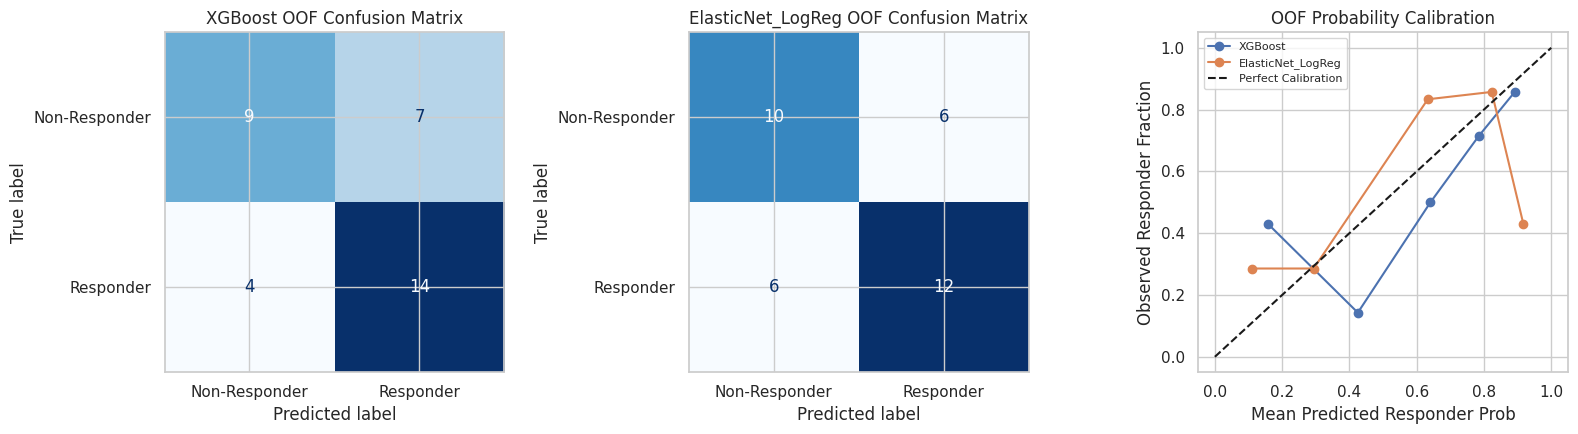

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, mname in zip(axes[:2], ["XGBoost", "ElasticNet_LogReg"]):
    cm = confusion_matrix(y_disc, (oof_probs[mname] >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Non-Responder", "Responder"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{mname} OOF Confusion Matrix")

for mname in ["XGBoost", "ElasticNet_LogReg"]:
    prob_true, prob_pred = calibration_curve(y_disc, oof_probs[mname], n_bins=5, strategy="quantile")
    axes[2].plot(prob_pred, prob_true, marker="o", label=mname)
axes[2].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
axes[2].set_title("OOF Probability Calibration")
axes[2].set_xlabel("Mean Predicted Responder Prob")
axes[2].set_ylabel("Observed Responder Fraction")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "m2_confusion_and_calibration.png"), dpi=150)
plt.show()

,Gene,Pathway,Selection_Freq,Mean_Abs_Weight,Signed_Weight,OCD_t_stat,OCD_pval
0,LOC389906,OCD Neuropathology,1.000000,1.094687,-1.094687,-3.739092,0.000290
1,PRPF40B,OCD Neuropathology,0.966667,0.332122,-0.332122,4.630728,0.000133
2,SEBOX,OCD Neuropathology,0.883333,0.161543,-0.161543,-5.180781,0.000001
3,UBE2F,OCD Neuropathology,0.533333,0.000056,0.000056,-4.326595,0.000247
4,TLR3,OCD Neuropathology,0.516667,0.097317,-0.097317,-4.534544,0.000023
5,RTTN,OCD Neuropathology,0.433333,0.090106,0.090106,-4.350027,0.000206
6,GNRHR,OCD Neuropathology,0.416667,0.059414,0.059414,-4.887649,0.000004
7,DYDC2,OCD Neuropathology,0.383333,0.032450,-0.032450,-4.203160,0.000084
8,XPNPEP1,OCD Neuropathology,0.366667,0.034563,-0.034563,-4.339079,0.000263
9,CPXM2,OCD Neuropathology,0.350000,0.058682,0.058682,-4.434736,0.000053


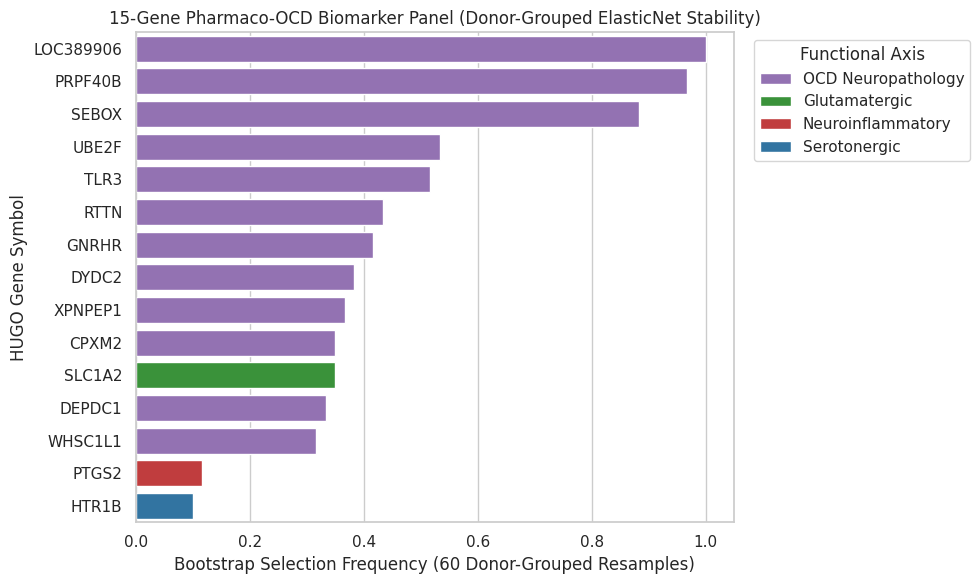

In [6]:
selected_genes, panel_df = run_stability_selection(
    X_disc,
    y_disc,
    g_disc,
    cand_genes,
    deg_df=deg_ocd,
    k=15,
    n_resamples=60,
    min_pathway_per_axis=1,
    random_state=42,
)
panel_path = os.path.join(DATA_PROCESSED_DIR, "biomarker_panel_15genes.csv")
panel_df.to_csv(panel_path, index=False)
display(panel_df)

plt.figure(figsize=(10, 6))
palette = {
    "Serotonergic": "#1f77b4",
    "Glutamatergic": "#2ca02c",
    "Neuroinflammatory": "#d62728",
    "OCD Neuropathology": "#9467bd",
}
sns.barplot(data=panel_df, y="Gene", x="Selection_Freq", hue="Pathway", palette=palette, dodge=False)
plt.title("15-Gene Pharmaco-OCD Biomarker Panel (Donor-Grouped ElasticNet Stability)")
plt.xlabel("Bootstrap Selection Frequency (60 Donor-Grouped Resamples)")
plt.ylabel("HUGO Gene Symbol")
plt.xlim(0, 1.05)
plt.legend(title="Functional Axis", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "m2_biomarker_panel_stability.png"), dpi=150)
plt.show()

In [7]:
ext_results, ext_probs = evaluate_external_cohort(
    X_disc, y_disc, X_ext, y_ext, selected_genes, ext_groups=g_ext, random_state=42
)
print("=== External Validation on Unseen Fluoxetine Cohort (GSE83386) ===")
display(ext_results)

model_path = os.path.join(MODELS_DIR, "pharmaco_ocd_classifier.joblib")
bundle = train_and_save_final_model(
    X_disc,
    y_disc,
    selected_genes,
    estimator=get_candidate_classifiers(42)["XGBoost"],
    output_path=model_path,
    metadata={
        "discovery_cohort": "GSE149980_CTP",
        "external_cohort": "GSE83386",
        "cv_results": cv_results.to_dict(orient="records"),
        "external_results": ext_results.to_dict(orient="records"),
    },
)

oof_tiers = pd.Series([stratify_risk_tier(p)["tier"] for p in oof_probs["XGBoost"]]).value_counts()
print("\nOOF XGBoost Risk Tier Stratification (SRS FR-03):")
display(oof_tiers.to_frame("Sample_Count"))

=== External Validation on Unseen Fluoxetine Cohort (GSE83386) ===


,Model,Ext_Sample_ROC_AUC,Ext_PR_AUC,Ext_Balanced_Acc,Ext_Brier_Score,Ext_Donor_ROC_AUC
0,L2_LogReg,0.489583,0.708928,0.375000,0.393882,0.458333
1,SVM_RBF,0.437500,0.606224,0.416667,0.448839,0.458333
2,ElasticNet_LogReg,0.437500,0.684920,0.333333,0.409342,0.416667
3,XGBoost,0.427083,0.613441,0.437500,0.436473,0.333333
4,RandomForest,0.427083,0.581642,0.479167,0.326495,0.375000
5,Dummy_Baseline,0.270833,0.523611,0.270833,0.700000,0.166667


[MODEL SAVED] /content/pharmaco-ocd/models/pharmaco_ocd_classifier.joblib | Genes=15 | Inference Latency=2.89 ms

OOF XGBoost Risk Tier Stratification (SRS FR-03):


,Sample_Count
Low Risk of Non-Response,16
High Risk of Non-Response,9
Moderate Risk of Non-Response,9
